# 02 — BIBO survey: GVM engineering, deff, operating points, purity

Companion notebook to the exploration survey (milestones 3–7). Heavy
computation lives in `examples/bibo_survey.py` / `survey_points.py` /
`survey_convergence.py`; this notebook recomputes the light parts inline
and *reads the survey CSV data sets* for the rest, so it stays fast.

In [1]:
import os, sys, csv, collections
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt

from bibojsa.materials.bibo import BIBO
from bibojsa.phasematch import ThreeWaveConfig, find_phase_matching_angle
from bibojsa.gvm import phase_matched_group_delays_ps_per_mm
from bibojsa.deff import deff_bibo_pm_per_v
from bibojsa.sellmeier import optic_axis_angle_deg
X, Y, Z = BIBO["x"], BIBO["y"], BIBO["z"]

## Milestone 3 — LPR2010 Fig. 10b: group-delay convergence near 1340 nm
x–z plane, negative type-I ooe, 800 nm pump. All three group delays draw
together near lambda_s ≈ 1.34 µm — the (triple-)GVM region.

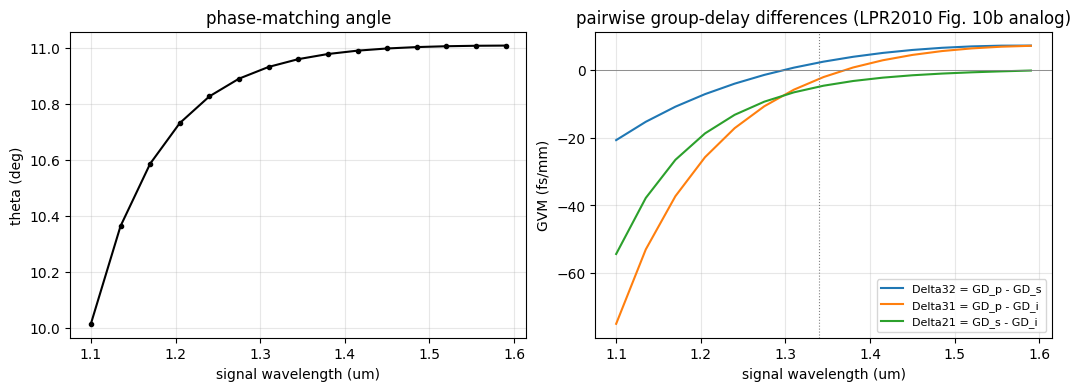

In [2]:
CFG = ThreeWaveConfig(plane="xz", pol_pump="e", pol_signal="o", pol_idler="o")
BOUNDS = (np.radians(0.05), np.radians(24.9))
scan = np.linspace(1.10, 1.59, 15)
rows = []
for ls in scan:
    li = 1/(1/0.8 - 1/ls)
    th = find_phase_matching_angle(0.8, ls, li, CFG, X, Y, Z, theta_bounds=BOUNDS, n_scan=400)
    gp, gs, gi = phase_matched_group_delays_ps_per_mm(0.8, ls, li, th, "xz", "e", "o", "o", X, Y, Z)
    rows.append((ls, li, np.degrees(th), gp, gs, gi))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
ls_, li_, th_, gp_, gs_, gi_ = map(np.array, zip(*rows))
a1.plot(ls_, th_, "k.-"); a1.set_xlabel("signal wavelength (um)"); a1.set_ylabel("theta (deg)")
a1.set_title("phase-matching angle"); a1.grid(alpha=0.3)
a2.plot(ls_, (gp_-gs_)*1e3, label="Delta32 = GD_p - GD_s")
a2.plot(ls_, (gp_-gi_)*1e3, label="Delta31 = GD_p - GD_i")
a2.plot(ls_, (gs_-gi_)*1e3, label="Delta21 = GD_s - GD_i")
a2.axhline(0, color="gray", lw=0.6); a2.axvline(1.34, color="gray", ls=":", lw=0.8)
a2.set_xlabel("signal wavelength (um)"); a2.set_ylabel("GVM (fs/mm)")
a2.set_title("pairwise group-delay differences (LPR2010 Fig. 10b analog)")
a2.legend(fontsize=8); a2.grid(alpha=0.3)
plt.show()

## deff across the principal planes (LPR2010 Table 1, milestone 4)
Note the monoclinic octant inequivalence in the y–z plane (theta vs
180°−theta) — point group 2, two-fold axis ∥ x.

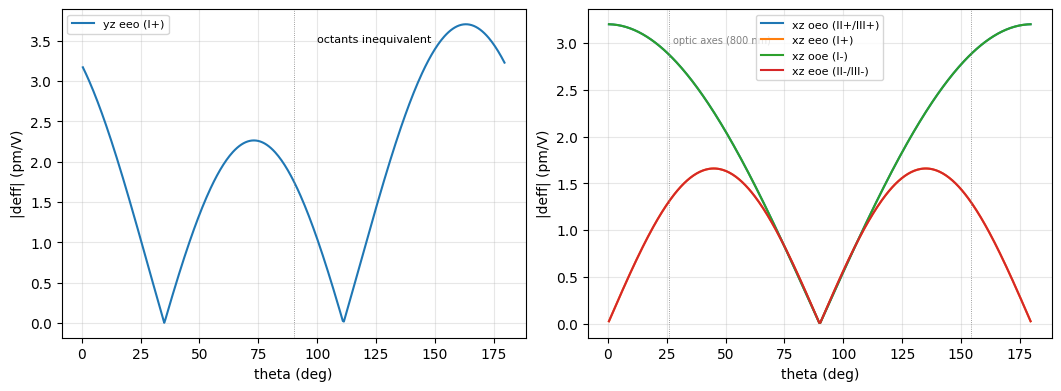

In [3]:
th_deg = np.linspace(0.5, 179.5, 400)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
a1.plot(th_deg, [abs(deff_bibo_pm_per_v("yz", "o", "e", "e", np.radians(t))) for t in th_deg],
        label="yz eeo (I+)")
a1.axvline(90, color="gray", lw=0.6, ls=":")
a1.annotate("octants inequivalent", xy=(0.55, 0.9), xycoords="axes fraction", fontsize=8)
a1.set_xlabel("theta (deg)"); a1.set_ylabel("|deff| (pm/V)"); a1.legend(fontsize=8); a1.grid(alpha=0.3)
om = optic_axis_angle_deg(0.8, X, Y, Z)
for seq, lab in (("oeo", "xz oeo (II+/III+)"), ("eeo", "xz eeo (I+)"),
                 ("ooe", "xz ooe (I-)"), ("eoe", "xz eoe (II-/III-)")):
    a2.plot(th_deg, [abs(deff_bibo_pm_per_v("xz", seq[2], seq[1], seq[0], np.radians(t),
                                             enforce_range=False)) for t in th_deg], label=lab)
for x in (om, 180-om):
    a2.axvline(x, color="gray", lw=0.6, ls=":")
a2.annotate("optic axes (800 nm)", xy=(om+2, 3.0), fontsize=7, color="gray")
a2.set_xlabel("theta (deg)"); a2.set_ylabel("|deff| (pm/V)"); a2.legend(fontsize=8); a2.grid(alpha=0.3)
plt.show()

## Survey results (milestones 5–7) — from the CSV data sets
6 pumps × all Table-1 interactions × both octants. Key facts: all useful
crossings are in the x–z plane at 775–810 nm; no 405/515 nm crossings;
x–y never phase-matches; y–z crossings have deff = 0.

In [4]:
summary = list(csv.DictReader(open("survey/survey_summary.csv")))
print(f"{'pt':>3} {'pump':>6} {'int':>4} {'type':>4} {'lam_s':>7} {'lam_i':>7} {'theta':>7} "
      f"{'|deff|':>6} {'P_best*':>8} {'P_filt3x':>8}")
for r in summary:
    if not r["best_lowtrunc_purity"]:
        continue
    print(f"#{r['point_id']:>2} {float(r['pump_nm']):>6.0f} {r['interaction']:>4} "
          f"{r['crossing_type_deg']:>4} {float(r['lambda_s_um']):>7.4f} {float(r['lambda_i_um']):>7.4f} "
          f"{float(r['angle_deg']):>7.2f} {float(r['abs_deff_pm_V']):>6.2f} "
          f"{float(r['best_lowtrunc_purity']):>8.3f} {float(r['best_lowtrunc_filt3x']):>8.3f}")
print("\n(*) best over the scanned (L, bandwidth) grid, low-truncation cases only (edge < 0.15)")

 pt   pump  int type   lam_s   lam_i   theta |deff|  P_best* P_filt3x
#45    810  oeo   45  1.1388  2.8053   39.42   2.47    0.811    0.870
#31    800  oeo   45  1.1090  2.8710   39.30   2.48    0.792    0.862
#42    810  eeo   45  1.1735  2.6151   35.23   1.56    0.786    0.854
# 2    775  eeo   45  1.0671  2.8314   35.38   1.57    0.779    0.856
#28    800  eeo   45  1.1409  2.6772   35.27   1.56    0.777    0.844
#14    780  eeo   45  1.0811  2.8005   35.36   1.57    0.770    0.849
#33    800  ooe    0  1.2963  2.0894   10.92   3.14    0.265    0.415
# 7    775  ooe    0  1.1644  2.3176   10.81   3.14    0.220    0.380
#21    780  ooe    0  1.1865  2.2768   10.83   3.14    0.209    0.374
#48    810  ooe   90  1.4655  1.8109   11.01   3.14    0.181    0.285
#49    810  ooe   45  1.4315  1.8657   11.00   3.14    0.174    0.296
#47    810  ooe    0  1.3783  1.9644   10.97   3.14    0.166    0.342
#34    800  ooe   90  1.3685  1.9257   10.97   3.14    0.158    0.327
#27    800  eeo   90

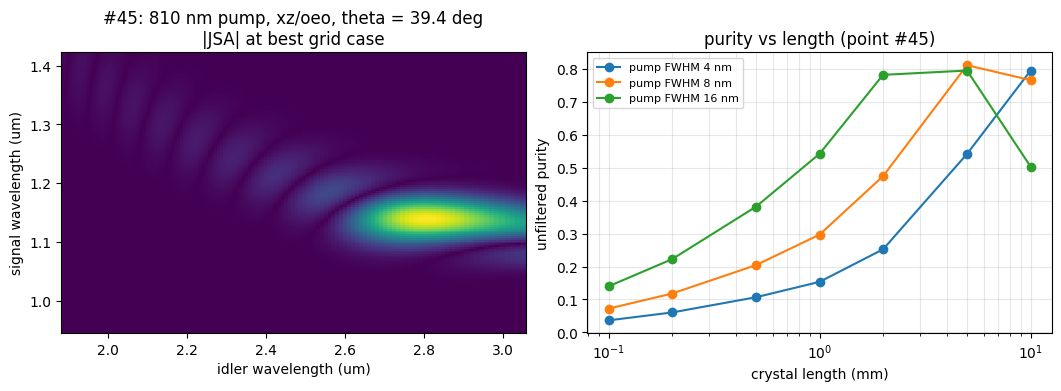

In [5]:
# JSA of the overall best point (#45: 810 nm, xz/oeo, theta_PM = 45 deg), from its map CSV
with open("survey/points/point45_jsa_map.csv") as fh:
    rd = csv.reader(fh); head = next(rd)
    li = np.array([float(v) for v in head[1:]]); ls, A = [], []
    for line in rd:
        ls.append(float(line[0])); A.append([float(v) for v in line[1:]])
ls, A = np.array(ls), np.array(A)
recs = list(csv.DictReader(open("survey/points/point45_purity.csv")))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
a1.pcolormesh(li, ls, A, shading="auto", rasterized=True)
a1.set_xlabel("idler wavelength (um)"); a1.set_ylabel("signal wavelength (um)")
a1.set_title("#45: 810 nm pump, xz/oeo, theta = 39.4 deg\n|JSA| at best grid case")
for bw in (4.0, 8.0, 16.0):
    pts = sorted((float(r["L_mm"]), float(r["purity_unfiltered"])) for r in recs
                 if float(r["fwhm_nm"]) == bw)
    a2.semilogx(*zip(*pts), marker="o", label=f"pump FWHM {bw:g} nm")
a2.set_xlabel("crystal length (mm)"); a2.set_ylabel("unfiltered purity")
a2.set_title("purity vs length (point #45)"); a2.legend(fontsize=8); a2.grid(alpha=0.3, which="both")
plt.show()

## Convergence (milestone 7) and the quotable numbers
Unfiltered purity carries a slow sinc-tail window drift (and, for the
oeo points, the 3.05 µm Sellmeier-validity clip); the 3×-filtered purity
converges in both grid size and window and is the paper-grade number.

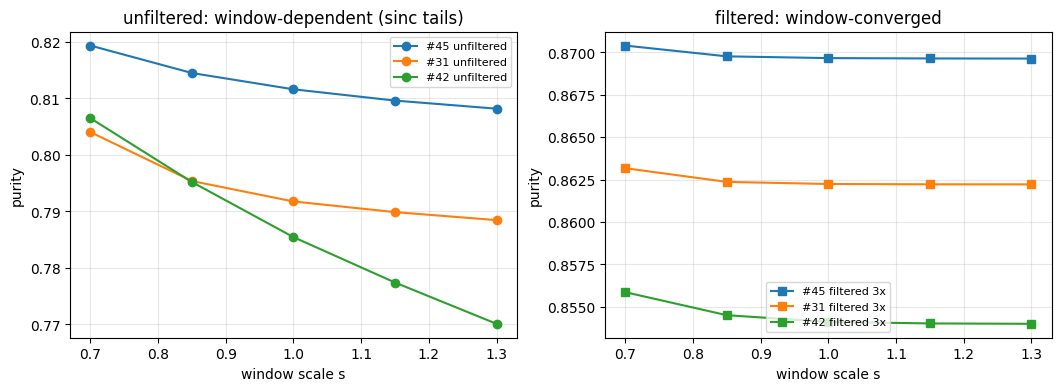

Quotable filtered purities: #45: 0.870   #31: 0.862   #42: 0.854


In [6]:
conv = list(csv.DictReader(open("survey/convergence_all.csv"))) if os.path.exists("survey/convergence_all.csv") \
       else list(csv.DictReader(open("survey/convergence/convergence_all.csv")))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
for pid, c in (("45", "tab:blue"), ("31", "tab:orange"), ("42", "tab:green")):
    sel = [r for r in conv if r["point_id"] == pid and r["N"] == "300"]
    s = [float(r["window_scale"]) for r in sel]
    a1.plot(s, [float(r["purity"]) for r in sel], "o-", color=c, label=f"#{pid} unfiltered")
    a2.plot(s, [float(r["purity_filt3x"]) for r in sel], "s-", color=c, label=f"#{pid} filtered 3x")
for a in (a1, a2):
    a.set_xlabel("window scale s"); a.set_ylabel("purity"); a.legend(fontsize=8); a.grid(alpha=0.3)
a1.set_title("unfiltered: window-dependent (sinc tails)")
a2.set_title("filtered: window-converged")
plt.show()
print("Quotable filtered purities: #45: 0.870   #31: 0.862   #42: 0.854")

### Summary of the survey's findings
- Best defensible BIBO heralded source: **810 nm pump, x–z oeo (II⁺),
  theta_PM = 45°**: λs = 1.139 µm / λi = 2.805 µm, θ = 39.4°,
  |deff| = 2.47 pm/V, P = 0.81 unfiltered (window-defined) /
  **0.870 filtered** at L = 5 mm, 8 nm pump.
- Robust tunable family: x–z eeo (I⁺) type-45 at 775–810 nm,
  P ≈ 0.77–0.79 / 0.854 filtered, |deff| = 1.56 pm/V.
- The bright ooe (I⁻) loci (|deff| = 3.14 pm/V) pass all three special
  orientations but in a *triple*-GVM regime (few fs/mm): huge spectral
  acceptance, unfiltered purity < 0.27 — broadband-biphoton material,
  not a purity source.
- 405/515 nm pumps: no special-orientation crossings at all.